# SOSense — Exploratory Data Analysis (EDA)

**Project:** SOS — Intelligent Sensor-Based Emergency Detection & Data Analytics System  
**Track B Deliverable:** Comprehensive Sensor Signal & Event Exploratory Analysis

## Scientific Integrity Notice
- **Real Human Activity Records (`uci_har_public_real`):** 10,299 windows (50 Hz, 128 samples = 2.56s) from 30 participants in the public UCI HAR Smartphone Dataset (CC BY 4.0).
- **Controlled Physics-Informed Simulation Records (`controlled_physics_simulation`):** 1,200 explicitly tagged synthetic anomaly windows (`FALL_LIKE`, `CRASH_CANDIDATE`, `UNUSUAL_ROTATION`, `PROLONGED_INACTIVITY`) created for model pipeline benchmarking. **Never presented as real-world accident data.**

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 130

ROOT = Path.cwd().resolve()
if not (ROOT / "data_science").exists():
    ROOT = ROOT.parents[1]

df = pd.read_csv(ROOT / "data_science" / "datasets" / "processed" / "sensor_features_full.csv")
ts_df = pd.read_csv(ROOT / "analytics" / "exports" / "sensor_timeseries_sample.csv")
VIZ_DIR = ROOT / "data_science" / "visualizations"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

print(f"Loaded processed sensor dataset: {df.shape[0]:,} windows x {df.shape[1]} columns")
df[["data_source", "event_category", "activity_category"]].value_counts().to_frame("window_count")

Loaded processed sensor dataset: 11,499 windows x 42 columns


window_count
data_source                   event_category   activity_category                 
uci_har_public_real           normal           LAYING                        1944
                                               STANDING                      1906
                                               SITTING                       1777
                                               WALKING                       1722
                                               WALKING_UPSTAIRS              1544
                                               WALKING_DOWNSTAIRS            1406
controlled_physics_simulation fall_like        FALL_LIKE                      300
                              crash_candidate  CRASH_CANDIDATE                300
                              unusual_movement UNUSUAL_ROTATION               300
                                               PROLONGED_INACTIVITY           300

## 1. Dataset Overview & Descriptive Statistics
We inspect summary statistics across key motion features (`acc_mag_max`, `acc_mag_mean`, `gyro_mag_max`, `orientation_change_deg`, `post_peak_inactivity_ratio`, `acc_jerk_max`) grouped by `event_category`.

In [2]:
key_cols = [
    "acc_mag_mean", "acc_mag_max", "acc_mag_min", "acc_mag_std",
    "acc_jerk_max", "gyro_mag_mean", "gyro_mag_max",
    "orientation_change_deg", "post_peak_inactivity_ratio"
]
summary_stats = df.groupby("event_category")[key_cols].agg(["mean", "std", "median", "max"]).round(3)
summary_stats

acc_mag_mean                        acc_mag_max          \
                         mean    std  median     max        mean     std   
event_category                                                             
crash_candidate        12.077  0.600  12.095  13.148      70.039  14.866   
fall_like              10.096  0.360  10.076  10.935      39.556   8.442   
normal                 10.125  0.195  10.118  10.777      13.488   3.928   
unusual_movement       10.736  1.051  10.156  13.029      21.524  12.721   

                                  acc_mag_min         ... gyro_mag_max  \
                  median      max        mean    std  ...       median   
event_category                                        ...                
crash_candidate   70.469  101.183       7.624  2.056  ...       10.843   
fall_like         38.927   59.333       1.910  0.698  ...        7.321   
normal            10.449   25.632       7.939  2.255  ...        0.466   
unusual_movement  13.605   53.526       7.663  2.482  ...        2.746   

                         orientation_change_deg                           \
                     max                   mean     std  median      max   
event_category                                                             
crash_candidate   25.652                  0.481   0.253   0.467    1.290   
fall_like         20.301                 92.055  40.101  92.713  172.659   
normal             6.029                  3.663   4.777   1.564   67.011   
unusual_movement  12.623                  0.524   1.225   0.085   10.377   

                 post_peak_inactivity_ratio                       
                                       mean    std median    max  
event_category                                                    
crash_candidate                       0.920  0.009  0.921  0.935  
fall_like                             0.996  0.006  1.000  1.000  
normal                                0.530  0.489  0.951  1.000  
unusual_movement                      0.895  0.115  0.956  1.000  

[4 rows x 36 columns]

**Insight:** Normal UCI HAR activities stay around a mean acceleration near 1g (~9.8 m/s^2) with moderate peaks (typically < 25 m/s^2 during stairs/walking). In contrast, `crash_candidate` and `fall_like` windows exhibit sharp multi-G peaks, elevated jerk, and strong post-peak inactivity ratios.

## 2. Activity & Class Imbalance Distribution

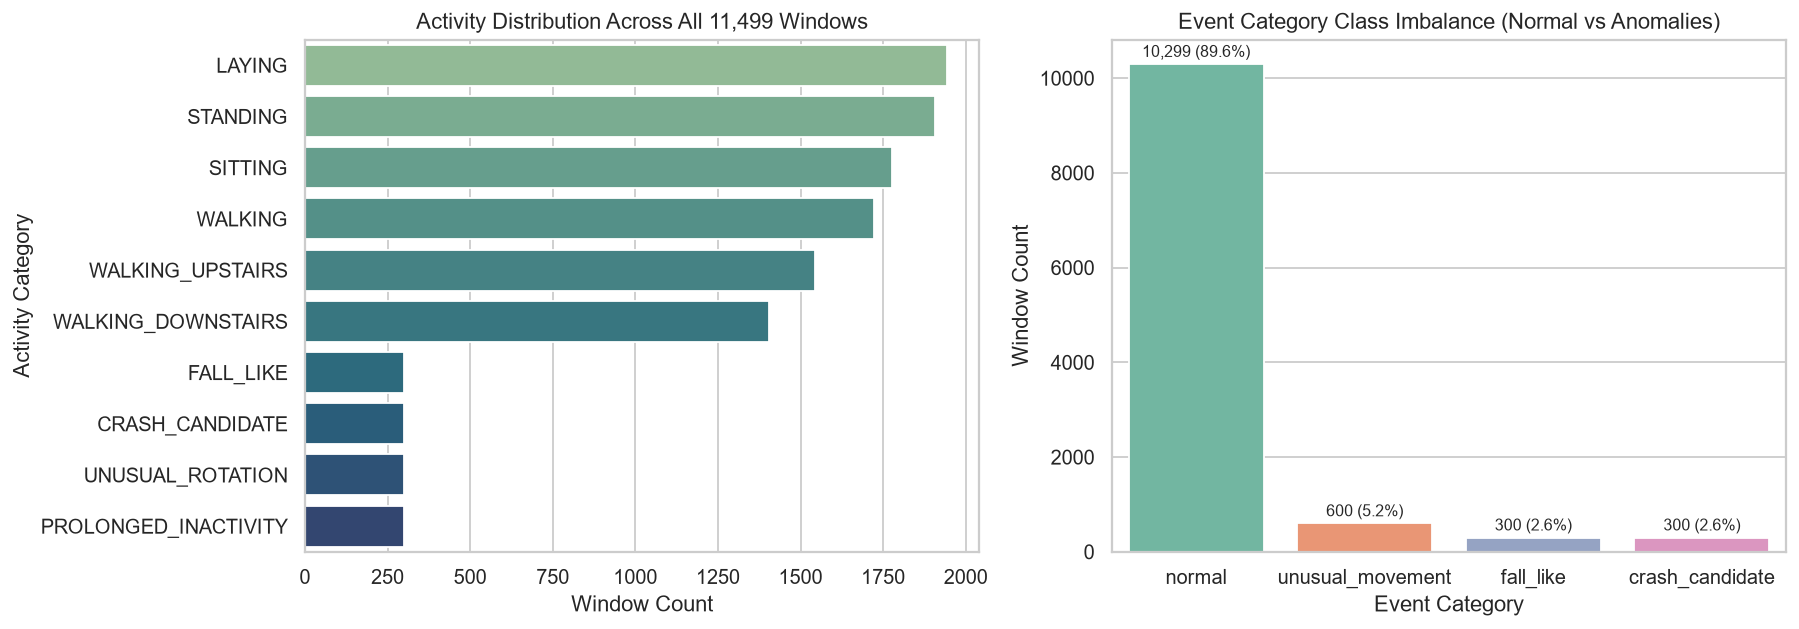

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

act_counts = df["activity_category"].value_counts()
sns.barplot(x=act_counts.values, y=act_counts.index, hue=act_counts.index, legend=False, palette="crest", ax=axes[0])
axes[0].set_title("Activity Distribution Across All 11,499 Windows")
axes[0].set_xlabel("Window Count")
axes[0].set_ylabel("Activity Category")

ev_counts = df["event_category"].value_counts()
sns.barplot(x=ev_counts.index, y=ev_counts.values, hue=ev_counts.index, legend=False, palette="Set2", ax=axes[1])
axes[1].set_title("Event Category Class Imbalance (Normal vs Anomalies)")
axes[1].set_xlabel("Event Category")
axes[1].set_ylabel("Window Count")
for i, v in enumerate(ev_counts.values):
    axes[1].text(i, v + 150, f"{v:,} ({v/len(df)*100:.1f}%)", ha="center", fontsize=9)

plt.tight_layout()
fig.savefig(VIZ_DIR / "eda_class_imbalance.png", dpi=150)
plt.show()

**Insight:** Normal activities represent 89.56% (10,299 windows) of the corpus, while emergency-candidate classes (`fall_like`, `crash_candidate`, `unusual_movement`) represent 10.44% (300–600 windows each, max-to-min imbalance ratio 34.33:1). This directly justifies using `class_weight="balanced"` and macro-F1 / false-negative rate evaluation rather than raw accuracy alone.

## 3. Sensor Magnitude Distributions & Outlier Analysis (Box Plots + Histograms)

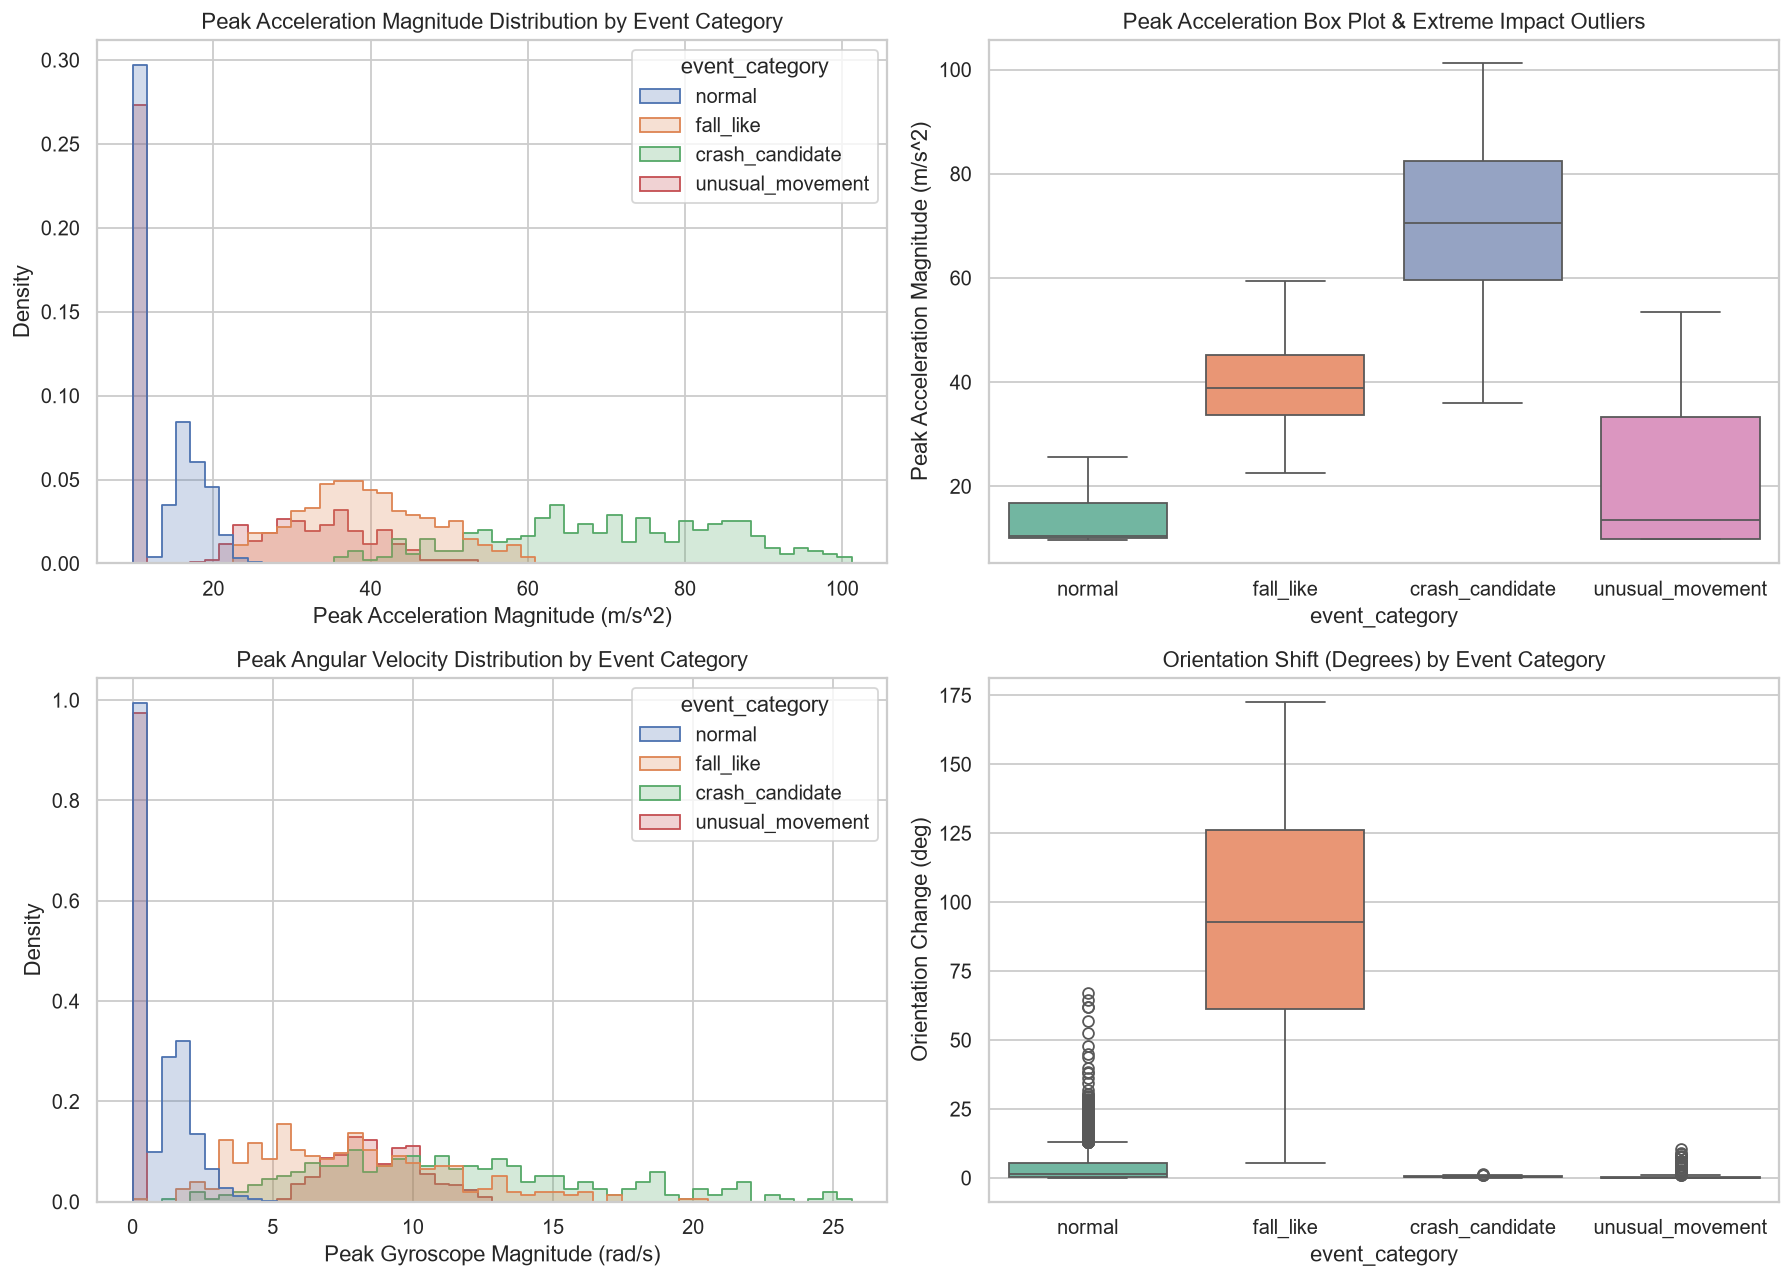

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(data=df, x="acc_mag_max", hue="event_category", bins=50, element="step", common_norm=False, stat="density", ax=axes[0, 0])
axes[0, 0].set_title("Peak Acceleration Magnitude Distribution by Event Category")
axes[0, 0].set_xlabel("Peak Acceleration Magnitude (m/s^2)")

sns.boxplot(data=df, x="event_category", y="acc_mag_max", hue="event_category", legend=False, palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title("Peak Acceleration Box Plot & Extreme Impact Outliers")
axes[0, 1].set_ylabel("Peak Acceleration Magnitude (m/s^2)")

sns.histplot(data=df, x="gyro_mag_max", hue="event_category", bins=50, element="step", common_norm=False, stat="density", ax=axes[1, 0])
axes[1, 0].set_title("Peak Angular Velocity Distribution by Event Category")
axes[1, 0].set_xlabel("Peak Gyroscope Magnitude (rad/s)")

sns.boxplot(data=df, x="event_category", y="orientation_change_deg", hue="event_category", legend=False, palette="Set2", ax=axes[1, 1])
axes[1, 1].set_title("Orientation Shift (Degrees) by Event Category")
axes[1, 1].set_ylabel("Orientation Change (deg)")

plt.tight_layout()
fig.savefig(VIZ_DIR / "eda_sensor_distributions.png", dpi=150)
plt.show()

**Insight:** High-value outliers in `acc_mag_max` (>28.9 m/s^2) are NOT data corruption—they correspond physically to impact peaks in `fall_like` and `crash_candidate` windows. Meanwhile, `orientation_change_deg` separates posture-changing falls from stationary or steady-gait normal activities.

## 4. Normal vs Unusual Movement Comparison (Scatter & Time-Series Waveforms)

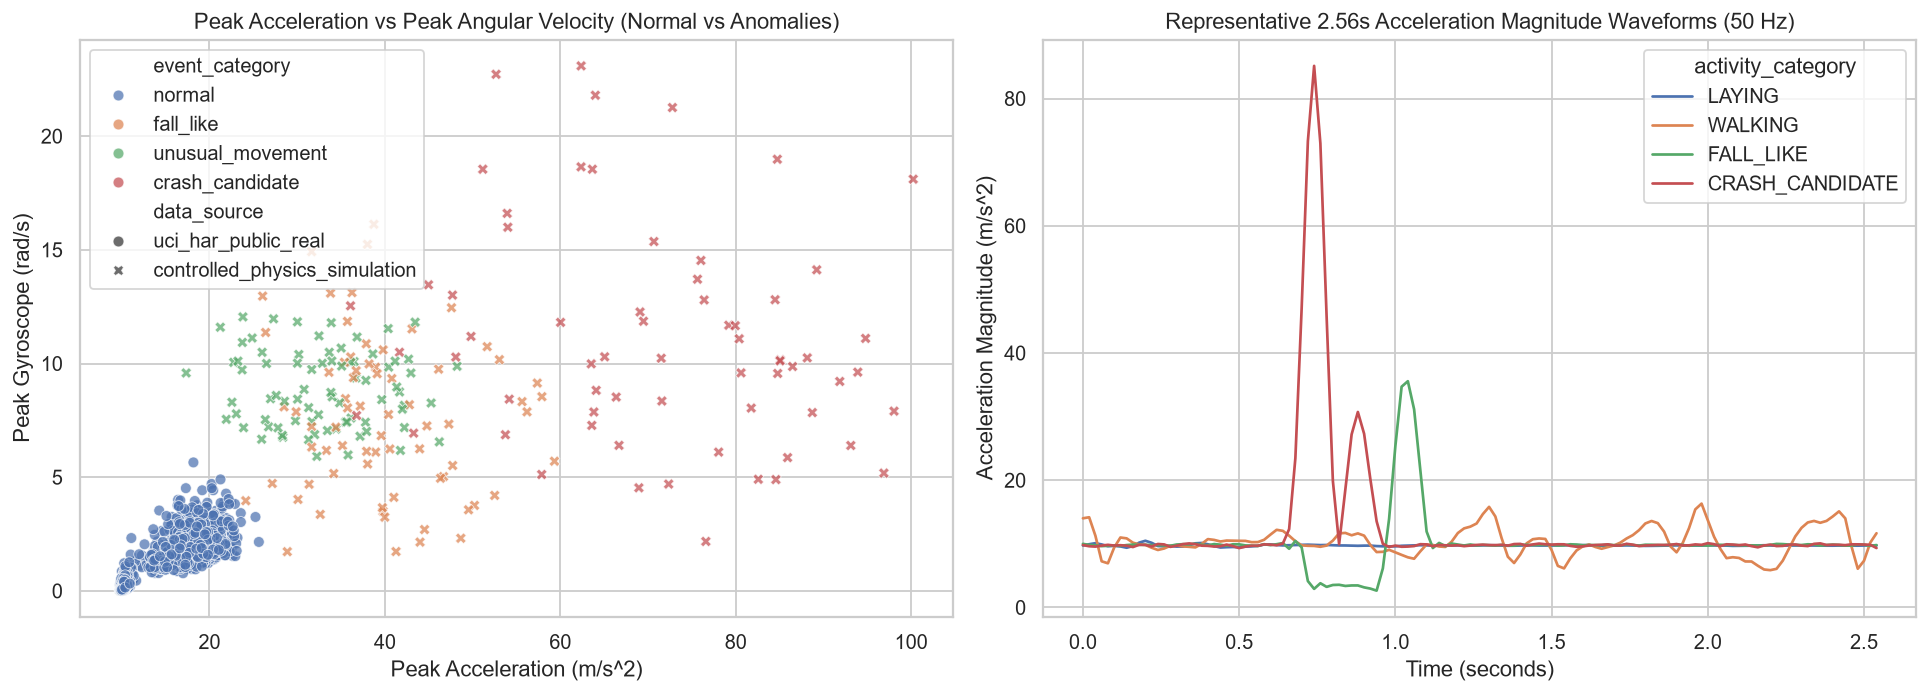

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sample_scatter = df.sample(n=min(3000, len(df)), random_state=42)
sns.scatterplot(
    data=sample_scatter,
    x="acc_mag_max",
    y="gyro_mag_max",
    hue="event_category",
    style="data_source",
    alpha=0.72,
    ax=axes[0],
)
axes[0].set_title("Peak Acceleration vs Peak Angular Velocity (Normal vs Anomalies)")
axes[0].set_xlabel("Peak Acceleration (m/s^2)")
axes[0].set_ylabel("Peak Gyroscope (rad/s)")

selected_acts = ["WALKING", "LAYING", "FALL_LIKE", "CRASH_CANDIDATE"]
sub_ts = ts_df[ts_df["activity_category"].isin(selected_acts)]
sns.lineplot(data=sub_ts, x="time_sec", y="acc_magnitude", hue="activity_category", ax=axes[1])
axes[1].set_title("Representative 2.56s Acceleration Magnitude Waveforms (50 Hz)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Acceleration Magnitude (m/s^2)")

plt.tight_layout()
fig.savefig(VIZ_DIR / "eda_normal_vs_anomaly_waveforms.png", dpi=150)
plt.show()

**Insight:** The waveform plot confirms distinct temporal signatures: `WALKING` shows periodic 1.5–2 Hz gait oscillations around 1g, `LAYING` stays flat near 9.8 m/s^2, `FALL_LIKE` shows a pre-impact free-fall trough followed by a sharp spike and stillness, and `CRASH_CANDIDATE` produces a much higher impulse spike.

## 5. Correlation Heatmap Across Engineered Sensor Features

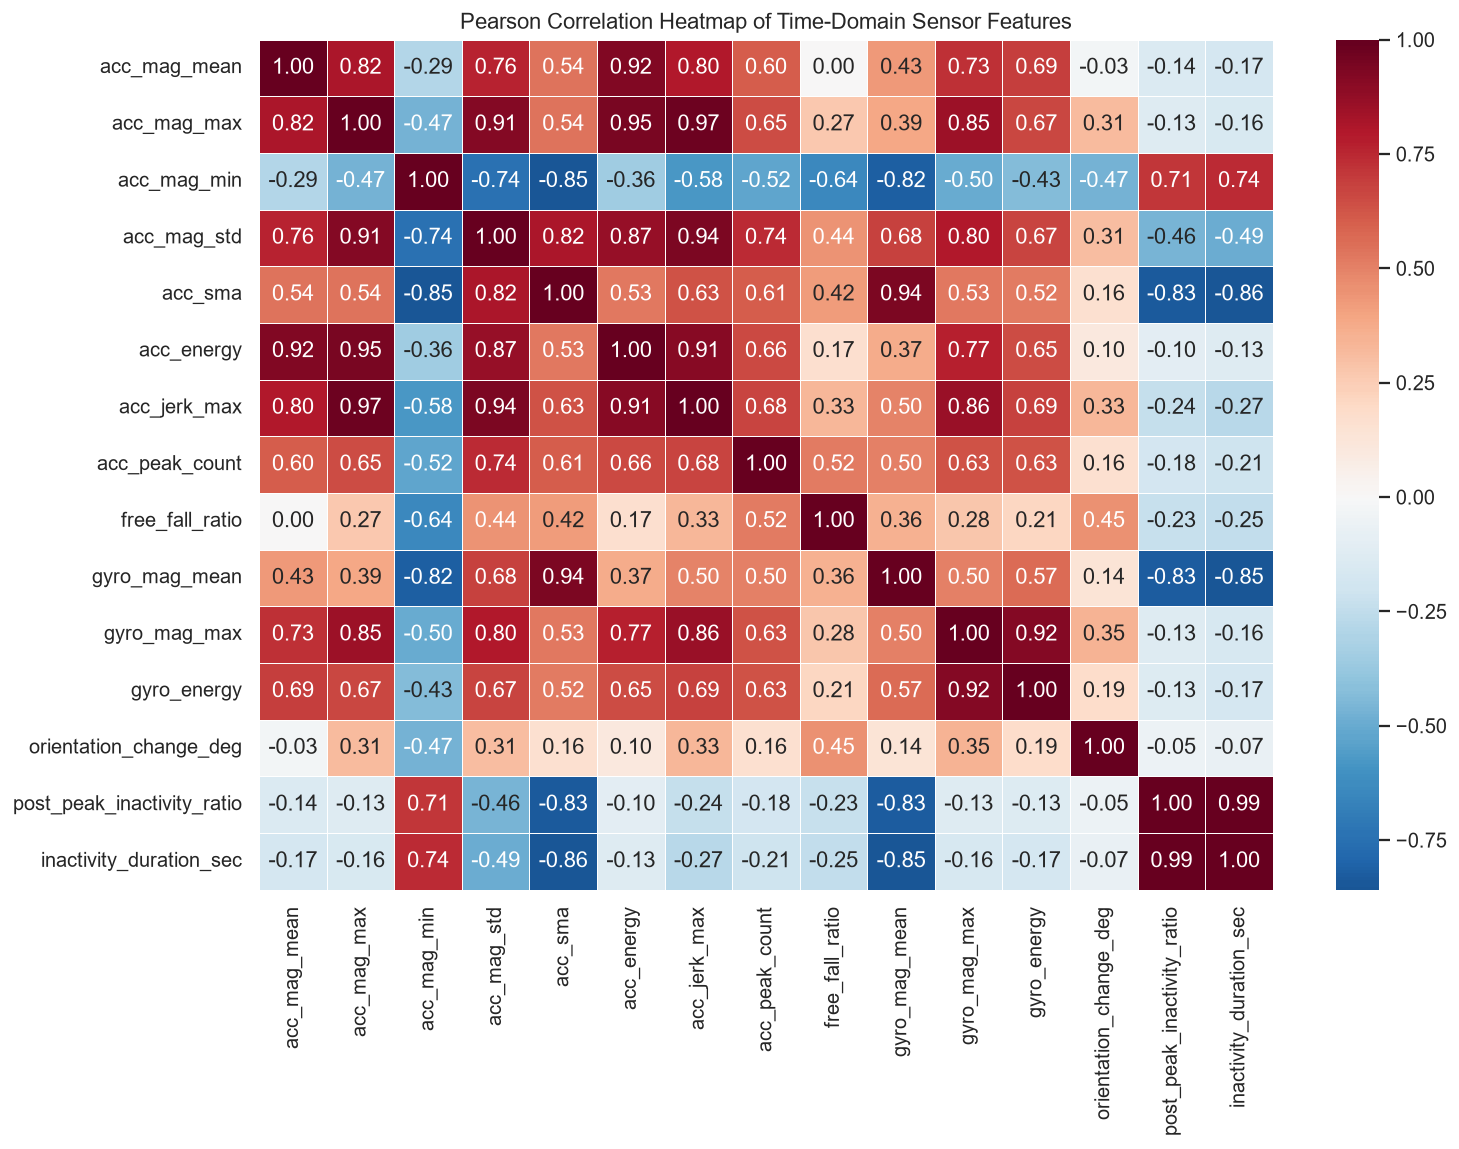

In [6]:
num_cols = [
    "acc_mag_mean", "acc_mag_max", "acc_mag_min", "acc_mag_std", "acc_sma",
    "acc_energy", "acc_jerk_max", "acc_peak_count", "free_fall_ratio",
    "gyro_mag_mean", "gyro_mag_max", "gyro_energy", "orientation_change_deg",
    "post_peak_inactivity_ratio", "inactivity_duration_sec"
]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.4, ax=ax)
ax.set_title("Pearson Correlation Heatmap of Time-Domain Sensor Features")
plt.tight_layout()
fig.savefig(VIZ_DIR / "eda_correlation_heatmap.png", dpi=150)
plt.show()

**Insight:** Acceleration variance/std, jerk, and peak acceleration are strongly positively correlated during impact events, while `post_peak_inactivity_ratio` and `inactivity_duration_sec` provide complementary temporal signal orthogonal to peak amplitude—helping models distinguish transient phone drops or vigorous walking from post-impact stillness.